# RiceShift
## NASA-Powered Rotation Advisor for California Rice Farms

**NASA Space Apps Challenge 2026 — Field Shift: Adapting Farms with NASA Data**  
**Team Hachi**

RiceShift asks a practical question:

> **Can NASA Earth observations add measurable evidence to crop-rotation decisions in California rice systems?**

Rather than beginning with a preferred crop rotation, this notebook tests three hypotheses and then combines those results with published soil and agronomic evidence.

### Candidate management strategies

1. **Continuous Rice**
2. **Rice → Winter Vetch → Rice**
3. **Rice → Winter Cover Crop Mix → Rice**

The goal is **decision support**, not a claim that one strategy is universally best.


# Research Design — From Challenge Objective to Testable Evidence

The Field Shift challenge calls for crop-rotation decision support that combines Earth observations with local agricultural context.

RiceShift translates that objective into three testable hypotheses:

### H1 — Seasonal environmental separation
**Winter soil-moisture conditions differ from rice-growing-season conditions.**

- Data: NASA SMAP
- Comparison: winter cover-crop window vs. rice season
- Method: paired **Wilcoxon signed-rank test**
- Effect size: **rank-biserial correlation**

### H2 — Environmental relevance to agricultural outcomes
**NASA-observed vegetation, water-use, and thermal indicators are associated with observed rice yield.**

- Data: NASA MODIS + USDA NASS
- Indicators: NDVI, EVI, LAI, ET, PET, land-surface temperature
- Method: **Spearman rank correlation**
- Uncertainty: **bootstrap 95% confidence intervals**
- Multiple comparisons: **Benjamini–Hochberg FDR correction**

### H3 — Out-of-sample predictive information
**NASA MODIS indicators contain useful information for predicting an unseen year's rice yield.**

- Data: NASA MODIS + USDA NASS
- Model: standardized **Ridge Regression**
- Validation: **Leave-One-Year-Out cross-validation**
- Benchmark: historical-mean prediction
- Metrics: **MAE, RMSE, R²**

### Agronomic / soil decision layer
The statistical hypotheses are followed by a separate soil-suitability screen using SSURGO and published California rice research.

This distinction is intentional:

> **Statistical evidence tells us what the observed data support. Published agronomic evidence helps interpret what management options are plausible.**


## Evidence flow

```text
GIS + 19-year crop history
            ↓
H1: Is winter a distinct environmental window?
            ↓
H2: Which NASA indicators relate to rice yield?
            ↓
H3: Do NASA indicators improve unseen-year prediction?
            ↓
SSURGO + published soil constraints
            ↓
Agronomic objective and farmer priorities
            ↓
Continuous Rice / Winter Vetch / Cover Crop Mix
```

The notebook therefore moves from **observation → hypothesis → statistical test → validation → decision support**.


# 1. Load the Analysis-Ready Bundle

The large source-data preparation pipeline does not need to be rerun for this experiment.

Download `data.zip` from the repository, open this notebook in **Google Colab**, and drag `data.zip` into the Colab Files panel.

Expected location:

```text
/content/data.zip
```

Expected ZIP structure:

```text
data.zip
├── step24/
├── step25/
├── step27/
├── step28/
├── step29/
└── step30/
```

Google Colab can be used without Google Drive for this notebook.


In [1]:
from pathlib import Path
import shutil
import zipfile
import subprocess
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, wilcoxon, rankdata

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

try:
    import rasterio
    from rasterio.vrt import WarpedVRT
    from rasterio.enums import Resampling
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])
    import rasterio
    from rasterio.vrt import WarpedVRT
    from rasterio.enums import Resampling

warnings.filterwarnings("ignore", category=RuntimeWarning)

ZIP_PATH = Path("/content/data.zip")
DATA_ROOT = Path("/content/riceshift_data")

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        "data.zip was not found at /content/data.zip.\n"
        "Upload data.zip using the Colab Files panel, then run this cell again."
    )

if DATA_ROOT.exists():
    shutil.rmtree(DATA_ROOT)

DATA_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATA_ROOT)

expected_steps = ["step24", "step25", "step27", "step28", "step29", "step30"]
missing_steps = [s for s in expected_steps if not (DATA_ROOT / s).exists()]

if missing_steps:
    raise RuntimeError(
        "Missing expected folder(s) in data.zip: " + ", ".join(missing_steps)
    )

print("RiceShift bundle ready.")
print("Data root:", DATA_ROOT)
print("Folders:", ", ".join(sorted(p.name for p in DATA_ROOT.iterdir())))


RiceShift bundle ready.
Data root: /content/riceshift_data
Folders: step24, step25, step27, step28, step29, step30


In [2]:
# Step 24 — MODIS/CDL analysis-ready features
monthly = pd.read_parquet(DATA_ROOT / "step24/monthly_features.parquet")
seasonal = pd.read_parquet(DATA_ROOT / "step24/seasonal_features.parquet")
winter = pd.read_parquet(DATA_ROOT / "step24/winter_cover_features.parquet")
full_year = pd.read_parquet(DATA_ROOT / "step24/full_year_features.parquet")

# Step 25 — USDA NASS outcomes joined to remote-sensing features
nass = pd.read_parquet(DATA_ROOT / "step25/model_yearly.parquet")

# Step 27 — NASA SMAP analysis-ready features
smap_daily = pd.read_parquet(DATA_ROOT / "step27/smap_daily.parquet")
smap_monthly = pd.read_parquet(DATA_ROOT / "step27/smap_monthly.parquet")
smap_seasonal = pd.read_parquet(DATA_ROOT / "step27/smap_seasonal.parquet")
smap_annual = pd.read_parquet(DATA_ROOT / "step27/smap_annual.parquet")

# Step 28 — CDL rotation history and GIS rasters
rotation = pd.read_csv(DATA_ROOT / "step28/yearly_group_counts.csv")
rotation_summary = pd.read_csv(DATA_ROOT / "step28/rotation_class_summary.csv")

# Step 29 — SSURGO soil properties
soil = pd.read_parquet(DATA_ROOT / "step29/ssurgo_mapunit_top30cm.parquet")

dataset_summary = pd.DataFrame({
    "Dataset": [
        "MODIS/CDL monthly",
        "MODIS/CDL seasonal",
        "Winter features",
        "NASS yearly",
        "SMAP daily",
        "SMAP seasonal",
        "CDL crop history",
        "SSURGO soil map units",
    ],
    "Rows": [
        len(monthly),
        len(seasonal),
        len(winter),
        len(nass),
        len(smap_daily),
        len(smap_seasonal),
        len(rotation),
        len(soil),
    ],
})

display(dataset_summary)


,Dataset,Rows
0,MODIS/CDL monthly,228
1,MODIS/CDL seasonal,19
2,Winter features,18
3,NASS yearly,19
4,SMAP daily,3820
5,SMAP seasonal,21
6,CDL crop history,19
7,SSURGO soil map units,4977


## Data used in this experiment

| Source | Variables used | Role |
|---|---|---|
| **NASA MODIS** | NDVI, EVI, LAI, ET, PET, daytime land-surface temperature | Vegetation, water-use, and thermal indicators |
| **NASA SMAP** | Surface soil moisture | Seasonal environmental comparison |
| **USDA CDL** | Rice and other crop classes, rice-year count | Long-term management history and GIS context |
| **USDA NASS** | Rice yield, harvested acres | Agricultural outcome |
| **USDA NRCS SSURGO** | pH, EC, Ksat, texture, organic matter, SAR | Soil constraints and agronomic context |

The statistical tests below use annual or seasonal aggregates rather than individual satellite pixels. The goal is a transparent hackathon-scale experiment, not a field-level causal model.


# 2. GIS Context — Where Has Rice Persisted?

Before testing the hypotheses, RiceShift establishes the spatial context.

The raster below counts the number of years a CDL pixel was classified as rice during **2007–2025**. Persistent rice areas are important because rotation feasibility cannot be interpreted independently of historical land use.


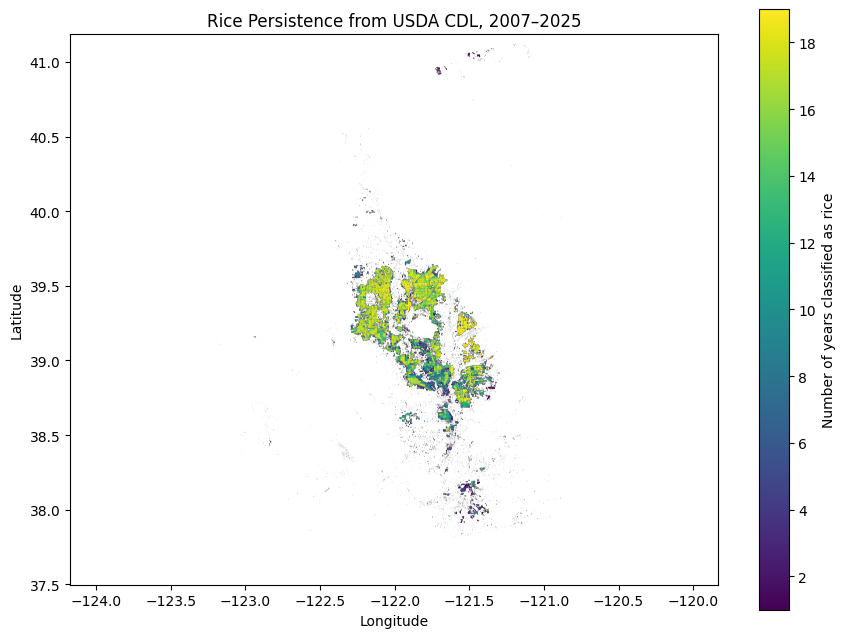

In [3]:
rice_year_tif = DATA_ROOT / "step28/raster/rice_year_count.tif"

with rasterio.open(rice_year_tif) as src:
    with WarpedVRT(
        src,
        crs="EPSG:4326",
        resampling=Resampling.nearest,
    ) as vrt:
        rice_years = vrt.read(1, masked=True)
        bounds = vrt.bounds

fig, ax = plt.subplots(figsize=(9, 8))
img = ax.imshow(
    rice_years,
    extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
    origin="upper",
)

ax.set_title("Rice Persistence from USDA CDL, 2007–2025")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

cbar = fig.colorbar(img, ax=ax, shrink=0.78)
cbar.set_label("Number of years classified as rice")

plt.tight_layout()
plt.show()


## 3,4,5 => Role of H1, H2, and H3 in RiceShift

H1, H2, and H3 are **not themselves crop-rotation recommendation models**.

Their role is to determine **what useful evidence can actually be extracted from NASA Earth-observation data**, and how confidently that evidence can be used in the RiceShift decision framework.

```text
H1 / H2 / H3
        ↓
Test what NASA data can reliably tell us
        ↓
Use those results as environmental evidence
        ↓
Combine with:
- long-term crop history
- SSURGO soil constraints
- agricultural outcomes
- published agronomic knowledge
        ↓
Screen:
Continuous Rice
vs.
Consider Winter Rotation
        ↓
If winter rotation is feasible:
Vetch
vs.
Cover Crop Mix
based on agronomic objectives
```

### Position of each hypothesis

- **H1 — Seasonal environmental separation**  
  Tests whether winter should be treated as a distinct management window rather than assuming rice-season conditions also represent winter.

- **H2 — Environmental relevance**  
  Tests which NASA-observed environmental indicators show meaningful relationships with rice yield and therefore may be useful as decision-support signals.

- **H3 — Predictive usefulness**  
  Tests whether those indicators collectively provide useful information for an unseen year, rather than only showing in-sample correlations.

Together, H1–H3 establish the **strength and limitations of the NASA evidence layer**.

The final crop-rotation screen is then made only after combining that evidence with crop history, soil constraints, and agronomic knowledge.

### Interpretation

This map is not itself a recommendation. It answers the first geographic question:

> **Where has rice actually persisted over the long term?**

RiceShift then adds environmental and soil evidence to this historical context.


# 3. Hypothesis 1 — Is Winter a Distinct Environmental Window?

## Hypothesis

> **H1: Winter soil-moisture conditions differ from rice-growing-season conditions.**

A winter cover crop occupies a different part of the agricultural calendar from rice. If winter moisture conditions are systematically different, then winter rotation feasibility should be evaluated as a separate environmental decision window.

### Data

NASA SMAP seasonal surface soil moisture:

- **Rice season:** April–November
- **Winter cover-crop season:** previous November–March
- Complete paired comparison: **2016–2025**

### Statistical test

Because the paired sample is small and normality should not be assumed, RiceShift uses the **paired Wilcoxon signed-rank test** rather than a paired t-test.

A rank-biserial correlation is also reported as a non-parametric effect-size measure.


In [4]:
rice_smap = (
    smap_seasonal.loc[
        smap_seasonal["season"] == "rice_apr_nov",
        ["year", "soil_moisture_mean"],
    ]
    .rename(columns={"soil_moisture_mean": "rice_smap"})
)

winter_smap = (
    smap_seasonal.loc[
        smap_seasonal["season"] == "winter_cover_nov_mar",
        ["year", "soil_moisture_mean"],
    ]
    .rename(columns={"soil_moisture_mean": "winter_smap"})
)

h1 = (
    rice_smap
    .merge(winter_smap, on="year", how="inner")
    .dropna()
    .sort_values("year")
)

h1["difference_winter_minus_rice"] = h1["winter_smap"] - h1["rice_smap"]

display(h1)


,year,rice_smap,winter_smap,difference_winter_minus_rice
0,2016,0.187423,0.315369,0.127946
1,2017,0.187851,0.350908,0.163056
2,2018,0.174285,0.296408,0.122123
3,2019,0.184575,0.320702,0.136127
4,2020,0.172096,0.283556,0.111460
5,2021,0.172861,0.278123,0.105262
6,2022,0.156051,0.281399,0.125348
7,2023,0.182742,0.316453,0.133711
8,2024,0.179626,0.312643,0.133017
9,2025,0.187861,0.329296,0.141435


In [5]:
# Paired Wilcoxon signed-rank test
w_stat, h1_p = wilcoxon(
    h1["winter_smap"],
    h1["rice_smap"],
    alternative="two-sided",
    method="auto",
)

# Matched-pairs rank-biserial correlation
diff = h1["difference_winter_minus_rice"].to_numpy()
nonzero = diff[diff != 0]

ranks = rankdata(np.abs(nonzero))
sum_pos = ranks[nonzero > 0].sum()
sum_neg = ranks[nonzero < 0].sum()
rank_biserial = (sum_pos - sum_neg) / (sum_pos + sum_neg)

h1_median_diff = float(np.median(diff))

print(f"Paired years: {len(h1)}")
print(f"Median winter - rice difference: {h1_median_diff:.4f} m³/m³")
print(f"Wilcoxon statistic: {w_stat:.3f}")
print(f"p-value: {h1_p:.4f}")
print(f"Rank-biserial correlation: {rank_biserial:.3f}")

if h1_p < 0.05:
    direction = "higher" if h1_median_diff > 0 else "lower"
    print(
        f"\nH1 result: The paired seasonal comparison detects a statistically "
        f"significant difference (p < 0.05); winter soil moisture is typically "
        f"{direction} than rice-season soil moisture in this sample."
    )
else:
    print(
        "\nH1 result: The paired seasonal comparison does not detect a "
        "statistically significant difference at alpha = 0.05."
    )


Paired years: 10
Median winter - rice difference: 0.1305 m³/m³
Wilcoxon statistic: 0.000
p-value: 0.0020
Rank-biserial correlation: 1.000

H1 result: The paired seasonal comparison detects a statistically significant difference (p < 0.05); winter soil moisture is typically higher than rice-season soil moisture in this sample.


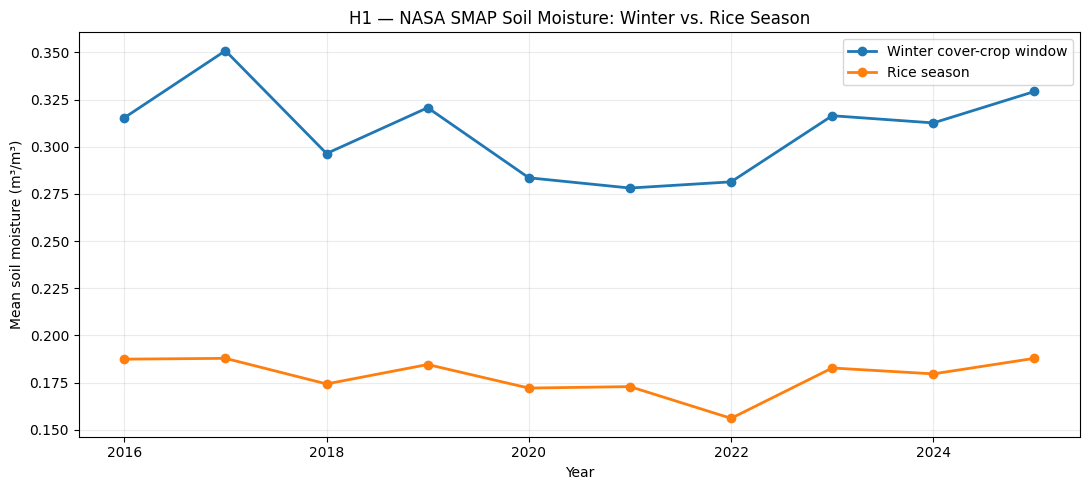

In [6]:
ax = h1.set_index("year")[["winter_smap", "rice_smap"]].plot(
    figsize=(11, 5),
    marker="o",
    linewidth=2,
)

ax.set_title("H1 — NASA SMAP Soil Moisture: Winter vs. Rice Season")
ax.set_xlabel("Year")
ax.set_ylabel("Mean soil moisture (m³/m³)")
ax.grid(alpha=0.25)
ax.legend(["Winter cover-crop window", "Rice season"])

plt.tight_layout()
plt.show()


### Decision meaning of H1

The paired NASA SMAP comparison supports **H1**.

Across the **10 paired years from 2016–2025**, winter soil moisture was consistently higher than rice-season soil moisture. The median difference was **+0.1305 m³/m³**.

The paired Wilcoxon signed-rank test showed a statistically significant seasonal difference (**p = 0.0020**), with a **rank-biserial correlation of 1.000**, indicating that all observed paired differences were in the same direction in this sample.

This gives RiceShift quantitative justification for treating winter as its **own management window**, rather than extrapolating rice-season environmental conditions into winter.

### Implication for the decision framework

The result does **not** mean that wetter winter conditions automatically favor a specific cover crop.

Instead, it supports a more limited and useful conclusion:

> **Winter rotation suitability should be evaluated using winter-specific environmental conditions.**

RiceShift therefore carries the winter SMAP signal forward into the next decision stages, where it is considered together with crop history, soil constraints, agricultural outcomes, and agronomic evidence.


# 4. Hypothesis 2 — Which NASA Indicators Are Associated with Rice Yield?

## Hypothesis

> **H2: NASA-observed vegetation, water-use, and thermal indicators are associated with annual California rice yield.**

The purpose is not to search for a convenient single correlation. RiceShift evaluates a predefined indicator set:

- **NDVI** — vegetation greenness
- **EVI** — vegetation condition with improved canopy/background sensitivity
- **LAI** — leaf area
- **ET** — evapotranspiration
- **PET** — potential evapotranspiration
- **LST** — daytime land-surface temperature

### Statistical design

For each indicator:

1. Spearman rank correlation with NASS rice yield
2. Two-sided p-value
3. Bootstrap 95% confidence interval
4. Benjamini–Hochberg false-discovery-rate adjustment across the six tests

This makes the analysis more resistant to cherry-picking.


In [7]:
h2_features = {
    "ndvi": "NDVI",
    "evi": "EVI",
    "lai": "LAI",
    "et": "ET",
    "pet": "PET",
    "lst_day_c": "Daytime LST",
}

target = "nass_yield_lb_acre"

missing_cols = [c for c in list(h2_features) + [target] if c not in nass.columns]
if missing_cols:
    raise KeyError("Missing expected H2 column(s): " + ", ".join(missing_cols))

h2_data = nass[
    ["year"] + list(h2_features.keys()) + [target]
].copy().sort_values("year")

display(h2_data)


,year,ndvi,evi,lai,et,pet,lst_day_c,nass_yield_lb_acre
0,2007,0.496080,0.321747,1.520028,421.469130,1440.000841,21.996449,8200.0
1,2008,0.494650,0.331292,1.517756,392.064175,1468.130151,21.729548,8320.0
2,2009,0.511877,0.343755,1.616155,426.409328,1430.848849,21.345898,8600.0
3,2010,0.518677,0.340924,1.605501,510.089267,1342.997280,18.975579,8020.0
4,2011,0.519049,0.338738,1.648802,515.844123,1336.584768,19.778025,8350.0
5,2012,0.523454,0.351205,1.574614,416.019016,1420.289870,19.635737,8150.0
6,2013,0.507312,0.339950,1.601245,426.472146,1515.808888,21.775063,8480.0
7,2014,0.497606,0.337393,1.433481,386.138497,1460.651869,22.543060,8580.0
8,2015,0.489388,0.341831,1.386986,368.323617,1469.637796,20.076544,8890.0
9,2016,0.509796,0.336219,1.615071,445.108437,1387.668977,21.810219,8840.0


In [8]:
def bootstrap_spearman_ci(x, y, n_boot=3000, seed=2026):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    n = len(x)

    boot = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        xb = x[idx]
        yb = y[idx]

        # Spearman is undefined if either resample is constant.
        if np.unique(xb).size < 2 or np.unique(yb).size < 2:
            continue

        rho, _ = spearmanr(xb, yb)
        if np.isfinite(rho):
            boot.append(rho)

    if not boot:
        return np.nan, np.nan

    return tuple(np.percentile(boot, [2.5, 97.5]))


def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]

    adjusted_ranked = ranked * n / np.arange(1, n + 1)
    adjusted_ranked = np.minimum.accumulate(adjusted_ranked[::-1])[::-1]
    adjusted_ranked = np.clip(adjusted_ranked, 0, 1)

    adjusted = np.empty(n, dtype=float)
    adjusted[order] = adjusted_ranked
    return adjusted


rows = []

for i, (col, label) in enumerate(h2_features.items()):
    pair = h2_data[[col, target]].dropna()

    rho, p = spearmanr(pair[col], pair[target])
    ci_low, ci_high = bootstrap_spearman_ci(
        pair[col],
        pair[target],
        n_boot=3000,
        seed=2026 + i,
    )

    rows.append({
        "indicator": label,
        "column": col,
        "n": len(pair),
        "rho": rho,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p,
    })

h2_results = pd.DataFrame(rows)
h2_results["q_value_fdr"] = benjamini_hochberg(h2_results["p_value"])
h2_results["abs_rho"] = h2_results["rho"].abs()
h2_results = h2_results.sort_values("abs_rho", ascending=False).reset_index(drop=True)

display(
    h2_results[
        ["indicator", "n", "rho", "ci_low", "ci_high", "p_value", "q_value_fdr"]
    ].round(4)
)


,indicator,n,rho,ci_low,ci_high,p_value,q_value_fdr
0,ET,19,-0.5476,-0.8259,-0.1300,0.0152,0.0914
1,PET,19,0.4563,0.0196,0.7761,0.0495,0.1486
2,LAI,19,-0.3993,-0.7695,0.1078,0.0903,0.1807
3,NDVI,19,-0.3668,-0.7610,0.1512,0.1224,0.1836
4,Daytime LST,19,0.1492,-0.3703,0.5606,0.5421,0.6316
5,EVI,19,-0.1176,-0.5695,0.4028,0.6316,0.6316


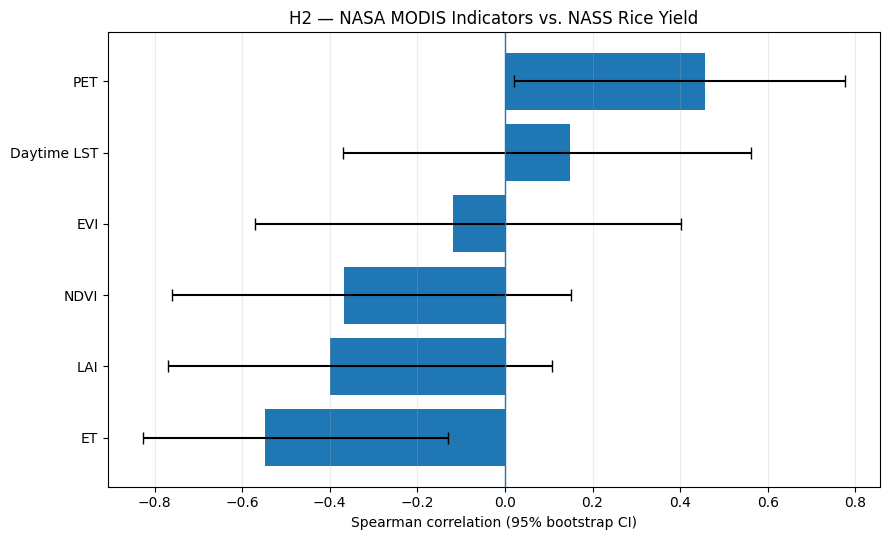

H2 summary:
No indicator remains significant at FDR q < 0.05. The strongest observed association is ET (rho=-0.548, raw p=0.0152).


In [9]:
plot_h2 = h2_results.sort_values("rho").copy()

lower_err = plot_h2["rho"] - plot_h2["ci_low"]
upper_err = plot_h2["ci_high"] - plot_h2["rho"]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(
    plot_h2["indicator"],
    plot_h2["rho"],
    xerr=np.vstack([lower_err, upper_err]),
    capsize=4,
)

ax.axvline(0, linewidth=1)
ax.set_title("H2 — NASA MODIS Indicators vs. NASS Rice Yield")
ax.set_xlabel("Spearman correlation (95% bootstrap CI)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

fdr_hits = h2_results[h2_results["q_value_fdr"] < 0.05]

print("H2 summary:")
if len(fdr_hits):
    print("Indicators remaining significant after FDR correction:")
    for _, row in fdr_hits.iterrows():
        direction = "positive" if row["rho"] > 0 else "negative"
        print(
            f"  - {row['indicator']}: rho={row['rho']:.3f}, "
            f"q={row['q_value_fdr']:.4f} ({direction})"
        )
else:
    strongest = h2_results.iloc[0]
    print(
        "No indicator remains significant at FDR q < 0.05. "
        "The strongest observed association is "
        f"{strongest['indicator']} (rho={strongest['rho']:.3f}, "
        f"raw p={strongest['p_value']:.4f})."
    )


### Decision meaning of H2

The H2 analysis found several potentially meaningful relationships between NASA MODIS indicators and annual California rice yield, but **none remained statistically significant after correction for multiple comparisons**.

The strongest observed association was **evapotranspiration (ET)**, which showed a moderate negative relationship with rice yield (**Spearman ρ = -0.548, raw p = 0.0152**). Its bootstrap 95% confidence interval ranged from approximately **-0.826 to -0.130**, remaining below zero.

**Potential evapotranspiration (PET)** showed the next strongest relationship, with a moderate positive association (**ρ = 0.456, raw p = 0.0495**), and a bootstrap 95% confidence interval of approximately **0.020 to 0.776**.

LAI and NDVI also showed moderate negative correlations, but their confidence intervals included zero. EVI and daytime land-surface temperature showed relatively weak associations with yield in this 19-year sample.

However, after applying the **Benjamini–Hochberg false-discovery-rate correction across all six indicators**, no relationship remained significant at **q < 0.05**. ET had the lowest adjusted value (**q = 0.0914**).

### Interpretation

Therefore, H2 is **not confirmed under the predefined multiple-testing criterion**.

At the same time, the results provide exploratory evidence that **water-related variables, particularly ET and PET, may contain information related to interannual rice-yield variability**.

This is an important distinction for RiceShift:

> **The data identify environmental signals worth carrying forward, but they do not yet justify treating any individual MODIS indicator as a confirmed driver of rice yield.**

The relatively small sample size (**19 annual observations**) also produces substantial uncertainty. These associations should therefore be interpreted as **candidate environmental signals**, not causal relationships.

### Implication for the decision framework

RiceShift does not select a crop-rotation strategy based on the strongest correlation alone.

Instead, the H2 results identify which NASA-observed environmental variables may deserve greater attention in the next stage. H3 then asks a stricter question:

> **Do these NASA indicators collectively provide useful information when predicting a year that the model has not seen before?**

This moves the analysis from exploratory association toward out-of-sample validation.


# 5. Hypothesis 3 — Can NASA Indicators Predict an Unseen Year's Yield?

## Hypothesis

> **H3: NASA MODIS indicators contain out-of-sample predictive information about rice yield.**

A model can fit a small historical dataset even when it has little real predictive value. Therefore, RiceShift evaluates each year as if it were unseen.

### Model

- Inputs: NDVI, EVI, LAI, ET, PET, daytime LST
- Model: Ridge Regression
- Feature standardization inside each training fold
- Hyperparameter selection inside the training data
- Outer validation: **Leave-One-Year-Out**

### Baseline

For every held-out year, the baseline predicts the **mean rice yield of the other training years**.

The NASA model is useful only if it improves on this simple benchmark.


In [10]:
ml_features = list(h2_features.keys())

ml = nass[
    ["year"] + ml_features + [target]
].dropna().sort_values("year").reset_index(drop=True)

X = ml[ml_features].to_numpy(dtype=float)
y = ml[target].to_numpy(dtype=float)
years = ml["year"].to_numpy()

outer_cv = LeaveOneOut()
alphas = np.logspace(-3, 3, 13)

pred_nasa = np.zeros(len(ml), dtype=float)
pred_baseline = np.zeros(len(ml), dtype=float)
selected_alpha = np.zeros(len(ml), dtype=float)

for train_idx, test_idx in outer_cv.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train = y[train_idx]

    # All preprocessing and alpha selection happen inside the outer training fold.
    model = Pipeline([
        ("scale", StandardScaler()),
        (
            "ridge",
            RidgeCV(
                alphas=alphas,
                cv=LeaveOneOut(),
                scoring="neg_mean_absolute_error",
            ),
        ),
    ])

    model.fit(X_train, y_train)

    pred_nasa[test_idx] = model.predict(X_test)
    pred_baseline[test_idx] = np.mean(y_train)
    selected_alpha[test_idx] = model.named_steps["ridge"].alpha_

h3_predictions = pd.DataFrame({
    "year": years,
    "actual_yield": y,
    "nasa_ridge_prediction": pred_nasa,
    "historical_mean_baseline": pred_baseline,
    "selected_alpha": selected_alpha,
})

display(h3_predictions.round(2))


,year,actual_yield,nasa_ridge_prediction,historical_mean_baseline,selected_alpha
0,2007,8200.0,8579.93,8543.89,100.00
1,2008,8320.0,8578.35,8537.22,100.00
2,2009,8600.0,8499.31,8521.67,100.00
3,2010,8020.0,8495.46,8553.89,100.00
4,2011,8350.0,8438.64,8535.56,100.00
5,2012,8150.0,8532.91,8546.67,31.62
6,2013,8480.0,8547.84,8528.33,100.00
7,2014,8580.0,8571.32,8522.78,100.00
8,2015,8890.0,8559.16,8505.56,100.00
9,2016,8840.0,8416.14,8508.33,31.62


In [11]:
def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }

nasa_metrics = regression_metrics(y, pred_nasa)
baseline_metrics = regression_metrics(y, pred_baseline)

h3_metrics = pd.DataFrame(
    [nasa_metrics, baseline_metrics],
    index=["NASA MODIS Ridge", "Historical-mean baseline"],
)

display(h3_metrics.round(3))

mae_improvement_pct = (
    (baseline_metrics["MAE"] - nasa_metrics["MAE"])
    / baseline_metrics["MAE"]
    * 100
)

print(f"NASA-model MAE improvement vs baseline: {mae_improvement_pct:.1f}%")

if nasa_metrics["MAE"] < baseline_metrics["MAE"]:
    print(
        "H3 result: The NASA MODIS Ridge model has lower leave-one-year-out "
        "MAE than the historical-mean baseline, indicating out-of-sample "
        "predictive information in the selected NASA indicators."
    )
else:
    print(
        "H3 result: The NASA MODIS Ridge model does not outperform the "
        "historical-mean baseline on leave-one-year-out MAE. These regional "
        "NASA indicators alone are therefore insufficient to claim improved "
        "yield prediction in this sample."
    )


,MAE,RMSE,R2
NASA MODIS Ridge,208.644,259.831,-0.049
Historical-mean baseline,210.234,267.833,-0.114


NASA-model MAE improvement vs baseline: 0.8%
H3 result: The NASA MODIS Ridge model has lower leave-one-year-out MAE than the historical-mean baseline, indicating out-of-sample predictive information in the selected NASA indicators.


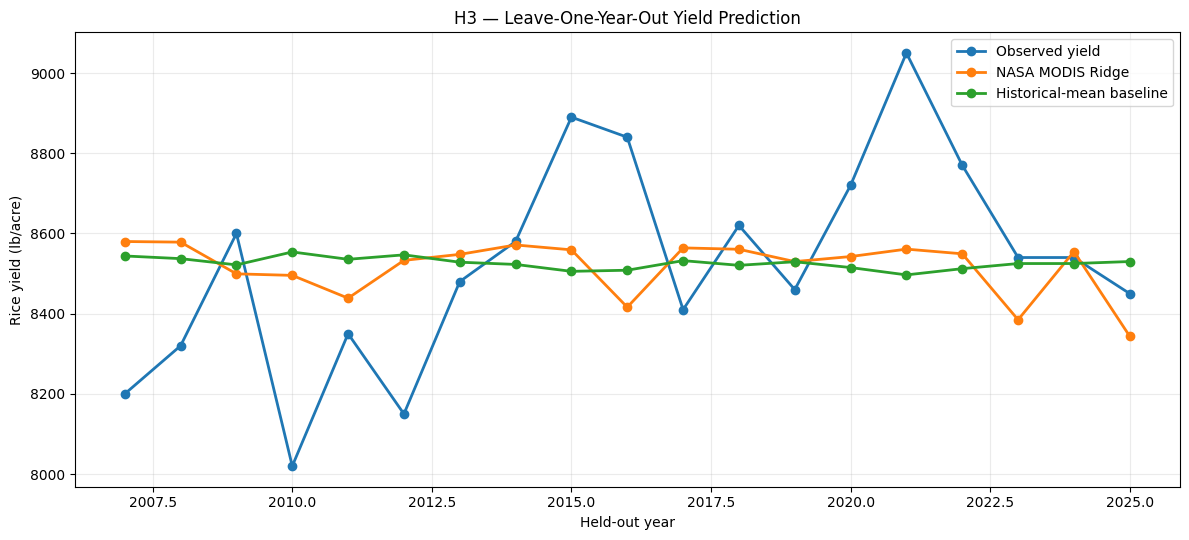

In [12]:
plot_h3 = h3_predictions.set_index("year")[
    ["actual_yield", "nasa_ridge_prediction", "historical_mean_baseline"]
]

ax = plot_h3.plot(
    figsize=(12, 5.5),
    marker="o",
    linewidth=2,
)

ax.set_title("H3 — Leave-One-Year-Out Yield Prediction")
ax.set_xlabel("Held-out year")
ax.set_ylabel("Rice yield (lb/acre)")
ax.legend(["Observed yield", "NASA MODIS Ridge", "Historical-mean baseline"])
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


### Decision meaning of H3

The NASA MODIS Ridge model performed **slightly better than the historical-mean baseline**, but the improvement was very small.

Under leave-one-year-out validation:

- **NASA MODIS Ridge MAE:** 208.6 lb/acre
- **Historical-mean baseline MAE:** 210.2 lb/acre
- **MAE improvement:** approximately **0.8%**
- **NASA MODIS Ridge RMSE:** 259.8 lb/acre
- **Historical-mean baseline RMSE:** 267.8 lb/acre
- **NASA MODIS Ridge R²:** -0.049
- **Historical-mean baseline R²:** -0.114

The NASA model therefore reduced average prediction error slightly, but the improvement over the simple baseline was **marginal**.

In addition, the NASA model's R² remained below zero. This indicates that the model did not explain the year-to-year yield variability well enough to support a strong predictive claim.

The prediction plot shows the same limitation: the Ridge model remains close to the long-term average and does not reproduce several of the larger observed yield changes.

### Interpretation

H3 is therefore **not strongly supported**.

The selected NASA MODIS indicators appear to contain some information—the Ridge model marginally outperformed the historical-mean baseline—but the improvement is too small to conclude that these regional indicators alone provide reliable out-of-sample yield prediction.

This result is consistent with H2: individual MODIS indicators showed some exploratory associations with yield, particularly ET and PET, but none remained significant after multiple-testing correction.

Together, H2 and H3 suggest that:

> **NASA environmental indicators contain potentially useful signals, but the current regional annual dataset is not sufficient by itself for accurate rice-yield prediction.**

### Implication for the decision framework

This is important for RiceShift because the system should **not use the yield model as a prediction engine or as the sole basis for selecting a crop rotation**.

Instead, NASA observations are used as one evidence layer alongside:

- long-term crop history,
- winter-specific SMAP conditions,
- soil constraints,
- agricultural outcomes,
- and published agronomic knowledge.

The next stage therefore shifts from asking whether NASA data can directly predict yield to asking how environmental observations and soil conditions can help **screen feasible management options**.

# 6. Soil Suitability Screen — SSURGO + Published California Rice Research

The soil layer is intentionally separated from H1–H3.

The compact dataset contains SSURGO map-unit soil properties, but it does not contain the field-boundary geometry needed to link each soil record directly to a specific farm outcome. For that reason, RiceShift does **not** manufacture a soil–yield correlation.

Instead, the notebook compares the observed SSURGO properties with published soil conditions associated with rice rotation in the Sacramento Valley.

## Published rotation-associated soil envelope

Salvato et al. (2024) combined satellite-derived land-cover history with SSURGO soil maps and a spatial random-forest model. They reported that rotated rice fields were more likely where:

- **pH:** 6.5–8.0
- **Electrical conductivity (EC):** 0.5–2 dS/m
- **Saturated hydraulic conductivity (Ksat):** < 2 μm/s

They also estimated that only about 11% of continuous-rice area in their study had all three properties together, emphasizing that soil can constrain expansion of rotation systems (Salvato et al., 2024).

RiceShift uses these thresholds as a **literature-based screening envelope**, not as a new causal rule.


In [13]:
soil_cols = {
    "ph1to1h2o_r_0_30cm": "pH",
    "ec_r_0_30cm": "EC",
    "ksat_r_0_30cm": "Ksat",
}

missing_soil = [c for c in soil_cols if c not in soil.columns]
if missing_soil:
    raise KeyError("Missing expected SSURGO column(s): " + ", ".join(missing_soil))

soil_screen = soil[list(soil_cols)].dropna().copy()

soil_screen["pH_match"] = soil_screen["ph1to1h2o_r_0_30cm"].between(
    6.5, 8.0, inclusive="both"
)
soil_screen["EC_match"] = soil_screen["ec_r_0_30cm"].between(
    0.5, 2.0, inclusive="both"
)
soil_screen["Ksat_match"] = soil_screen["ksat_r_0_30cm"] < 2.0

soil_screen["criteria_matched"] = (
    soil_screen[["pH_match", "EC_match", "Ksat_match"]]
    .sum(axis=1)
    .astype(int)
)

criterion_summary = pd.DataFrame({
    "Criterion": [
        "pH 6.5–8.0",
        "EC 0.5–2 dS/m",
        "Ksat < 2 μm/s",
        "All three criteria",
    ],
    "Map-unit records": [
        int(soil_screen["pH_match"].sum()),
        int(soil_screen["EC_match"].sum()),
        int(soil_screen["Ksat_match"].sum()),
        int((soil_screen["criteria_matched"] == 3).sum()),
    ],
})

criterion_summary["Percent of complete records"] = (
    criterion_summary["Map-unit records"] / len(soil_screen) * 100
)

display(criterion_summary.round(1))

print(f"Complete SSURGO records used: {len(soil_screen):,}")
print(
    "Important: these percentages are percentages of analyzed SSURGO "
    "map-unit records, not percentages of Sacramento Valley acreage."
)


,Criterion,Map-unit records,Percent of complete records
0,pH 6.5–8.0,1830,38.3
1,EC 0.5–2 dS/m,662,13.8
2,Ksat < 2 μm/s,452,9.5
3,All three criteria,151,3.2


Complete SSURGO records used: 4,780
Important: these percentages are percentages of analyzed SSURGO map-unit records, not percentages of Sacramento Valley acreage.


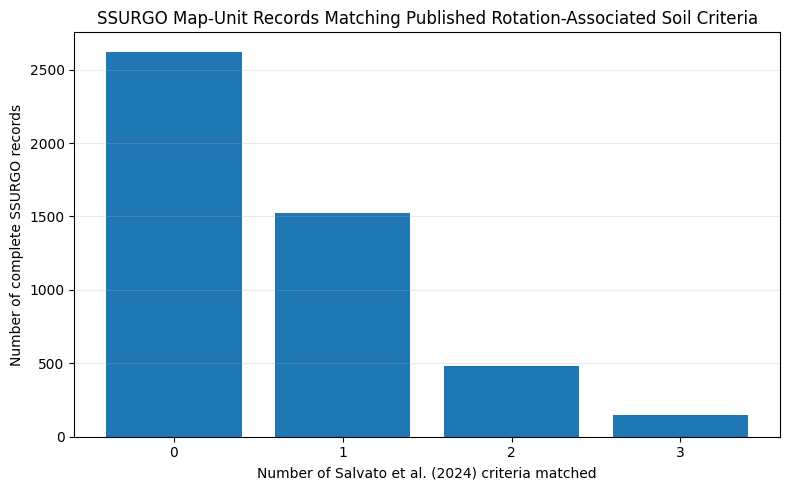

In [14]:
score_counts = (
    soil_screen["criteria_matched"]
    .value_counts()
    .reindex([0, 1, 2, 3], fill_value=0)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(score_counts.index.astype(str), score_counts.values)

ax.set_title(
    "SSURGO Map-Unit Records Matching Published Rotation-Associated Soil Criteria"
)
ax.set_xlabel("Number of Salvato et al. (2024) criteria matched")
ax.set_ylabel("Number of complete SSURGO records")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


### Why soil matters for the final decision

The SSURGO screening shows that the soil conditions associated with crop rotation in previous Sacramento Valley research are **not common across the analyzed map-unit records**.

Among the **4,780 SSURGO records** with complete pH, EC, and Ksat information:

- **38.3%** matched the published pH range of **6.5–8.0**
- **13.8%** matched the EC range of **0.5–2 dS/m**
- **9.5%** had **Ksat < 2 μm/s**
- only **3.2%** matched **all three criteria simultaneously**

The distribution of matched criteria also shows that most analyzed soil records satisfy either none or only part of the published rotation-associated soil envelope.

These results suggest that **soil may substantially constrain where crop diversification is agronomically plausible**, even before climate, management history, or farmer objectives are considered.

This is consistent with California rice production guidance. Flooded rice systems benefit from soils that can retain ponded water, and rice-growing areas often contain clay-rich or restrictive soils with low infiltration rates (Al-Khatib et al., 2023). However, those same characteristics can make diversification into alternative crops more difficult.

> **A soil condition that supports flooded rice can simultaneously limit the feasibility of crop rotation.**

### Implication for RiceShift

The soil screen therefore acts as a **feasibility filter**, not as a yield predictor.

RiceShift should not recommend winter rotation based only on NASA environmental signals. A location may appear environmentally suitable for winter management but still have soil properties that make diversification difficult.

The resulting decision logic becomes:

> **Environmental opportunity does not automatically imply agronomic feasibility.**

For that reason, RiceShift combines the NASA evidence layer with SSURGO-based soil constraints before moving from **Continuous Rice** toward **Consider Winter Rotation**.

### Important limitation

These percentages describe the proportion of **analyzed SSURGO map-unit records**, not the proportion of Sacramento Valley land area or individual rice fields.

Because the compact dataset does not include field-boundary geometry or area-weighted soil polygons, the results should be interpreted as a regional soil-context screen rather than a field-level suitability map.


# 7. From "Consider Rotation" to "Which Rotation?"

The previous analyses establish what the current data can and cannot support.

- **H1** showed that winter is a distinct environmental management window.
- **H2** identified potentially useful NASA environmental signals, while also showing substantial uncertainty.
- **H3** showed that the current regional NASA indicators alone are not sufficient for reliable yield prediction.
- The **SSURGO soil screen** showed that soil can be an important constraint on diversification.

Together, these results suggest that NASA and USDA observations are best used as a **screening layer**, rather than as an automated crop-selection model.

The first decision is therefore:

> **Do the field history, winter environmental conditions, and soil context justify considering a winter rotation?**

If the answer is **no**, Continuous Rice remains the more plausible candidate.

If the answer is **yes**, RiceShift moves to a second decision:

> **What type of winter rotation best matches the agronomic objective?**

The current regional dataset cannot directly prove that **vetch** is better than a **cover-crop mixture**, or vice versa. The second-stage choice therefore uses published agronomic evidence.

## Winter Vetch

California rice guidance identifies vetch among leguminous cover crops. Legumes can fix atmospheric nitrogen and contribute nitrogen to the cropping system (Al-Khatib et al., 2023).

**RiceShift interpretation:**  
Vetch is a reasonable candidate when the grower's primary objective includes **biological nitrogen contribution**, provided winter moisture, drainage, planting timing, and field conditions are suitable.

## Winter Cover Crop Mix

Published California rice guidance also discusses combinations of legumes and non-legumes. Non-legume species with higher C:N ratios can slow residue decomposition and nitrogen release, while mixtures can provide a broader set of functions than a single-species cover crop (Al-Khatib et al., 2023; Brim-DeForest et al., 2023).

**RiceShift interpretation:**  
A cover-crop mixture is a reasonable candidate when the objective emphasizes **diversity, soil cover, nutrient retention, and multiple ecosystem functions**, provided the soil and winter management window are suitable.

## Why There Is No Universal Winner

The final crop choice cannot be made from satellite observations alone.

California grower research shows that rotation adoption also depends on factors such as:

- soil suitability,
- profitability,
- market access,
- equipment,
- water management,
- timing,
- and grower objectives

(Rosenberg et al., 2022).

RiceShift therefore uses a **two-stage decision process**:

```text
NASA + USDA + Crop History + Soil
                ↓
Is winter rotation worth considering?
        ↓                    ↓
       NO                   YES
        ↓                    ↓
Continuous Rice      What is the farm objective?
                             ↓
                  ┌──────────┴──────────┐
                  ↓                     ↓
          Nitrogen contribution   Broader soil-cover /
                  ↓               diversity functions
                Vetch                   ↓
                                 Cover Crop Mix
```

The final output is therefore a **decision-support screen**, not an automated claim that one crop rotation is universally optimal.


## 7A. Quantitative Published Evidence — What Value Can a Winter Rotation Add?

The NASA / USDA / SSURGO analysis answers whether a winter rotation is worth **considering**.  
The next question is different:

> **If a winter rotation is feasible, what measurable agronomic or economic value might it provide?**

To answer that question, RiceShift adds a second evidence layer from published California rice and Sacramento Valley field research.

This layer is intentionally kept separate from H1–H3.

The published experiments were conducted at different sites and in different years from the regional MODIS / SMAP time series. Combining them row-by-row and calculating a new correlation would create false precision and pseudo-replication.

Instead, RiceShift uses the published trials for what they actually support:

1. **Vetch → fertilizer-N replacement and subsequent rice yield response**
2. **Vetch vs. mixtures → biomass and N contribution under rice-field winter conditions**
3. **Regional cover-crop cost → an economic sensitivity benchmark**

> **The evidence is combined at the decision level, not artificially merged into one statistical dataset.**


### 7A-1. Vetch Changes the Nitrogen–Yield Tradeoff

Pettygrove and Williams (1996) summarized long-term California rice-cover-crop experiments and reported that vetch reduced rice fertilizer-N requirements by **30–100 lb N/acre**, averaging approximately **50 lb N/acre** across experiments.

One five-year experiment at the Rice Experiment Station compared purple vetch with no cover crop across four fertilizer-N rates.

The important question is not simply whether vetch "increases yield."

Instead:

> **Does vetch change how much synthetic nitrogen is needed to achieve a given rice yield?**


,N_applied_lb_ac,Purple_vetch_cwt_ac,No_cover_crop_cwt_ac,Vetch_yield_difference_cwt_ac
0,0,43,27,16
1,40,51,41,10
2,80,56,52,4
3,120,54,57,-3


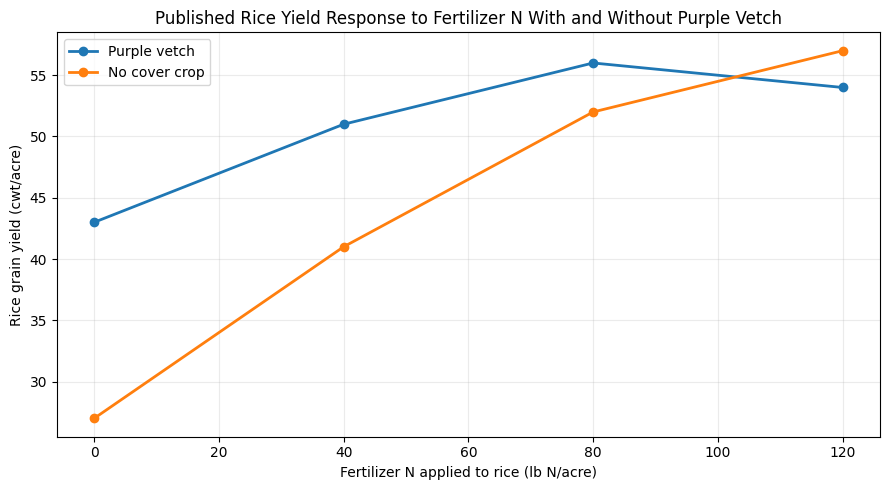

Yield difference (vetch - no cover crop):
  N=  0 lb/ac: +16.0 cwt/ac
  N= 40 lb/ac: +10.0 cwt/ac
  N= 80 lb/ac: +4.0 cwt/ac
  N=120 lb/ac: -3.0 cwt/ac


In [15]:
# Published five-year average rice-yield response to purple vetch
# Source: Pettygrove & Williams (1996), Table 4.
vetch_rice_response = pd.DataFrame({
    "N_applied_lb_ac": [0, 40, 80, 120],
    "Purple_vetch_cwt_ac": [43, 51, 56, 54],
    "No_cover_crop_cwt_ac": [27, 41, 52, 57],
})

vetch_rice_response["Vetch_yield_difference_cwt_ac"] = (
    vetch_rice_response["Purple_vetch_cwt_ac"]
    - vetch_rice_response["No_cover_crop_cwt_ac"]
)

display(vetch_rice_response)

ax = vetch_rice_response.set_index("N_applied_lb_ac")[
    ["Purple_vetch_cwt_ac", "No_cover_crop_cwt_ac"]
].plot(
    figsize=(9, 5),
    marker="o",
    linewidth=2,
)

ax.set_title("Published Rice Yield Response to Fertilizer N With and Without Purple Vetch")
ax.set_xlabel("Fertilizer N applied to rice (lb N/acre)")
ax.set_ylabel("Rice grain yield (cwt/acre)")
ax.legend(["Purple vetch", "No cover crop"])
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Yield difference (vetch - no cover crop):")
for _, row in vetch_rice_response.iterrows():
    print(
        f"  N={int(row['N_applied_lb_ac']):3d} lb/ac: "
        f"{row['Vetch_yield_difference_cwt_ac']:+.1f} cwt/ac"
    )


### Interpretation — Vetch Is Primarily an N-Management Strategy

The five-year experiment shows a clear interaction between cover cropping and fertilizer management.

- At **0 lb N/acre**, purple vetch plots yielded **16 cwt/acre more** than the no-cover treatment.
- At **40 lb N/acre**, the difference was **+10 cwt/acre**.
- At **80 lb N/acre**, the difference narrowed to **+4 cwt/acre**.
- At **120 lb N/acre**, the vetch treatment was **3 cwt/acre lower**.

Pettygrove and Williams (1996) interpreted the vetch effect in this experiment as equivalent to roughly **40 lb N/acre**. Across several California experiments, vetch reduced fertilizer-N requirement by **30–100 lb N/acre**, averaging about **50 lb N/acre**.

This changes the RiceShift interpretation of "Winter Vetch":

> **Vetch should not be evaluated as an extra crop whose value comes only from additional harvest. Its major measurable value can be nitrogen supplied to the following rice crop and a reduction in synthetic fertilizer requirement.**

It also shows why fertilizer management must change after a successful legume cover crop. Applying the same high N rate used without vetch can erase the benefit and may even reduce yield.

This is direct agronomic evidence for a **Vetch → Rice** strategy, but it does not imply that every field or every year will produce the same response (Pettygrove & Williams, 1996).


### 7A-2. Vetch vs. Cover-Crop Mixtures Under Wet Rice-Field Conditions

A 2022–2023 California rice cover-crop variety trial tested single species and mixtures across rice-region sites. That winter was unusually wet and establishment was poor at most locations; meaningful spring biomass data were available primarily from the Colusa site.

Because this was a difficult establishment year, the results are useful as a **stress-case observation**, not as a universal ranking.

The table below reproduces the published Colusa treatment means for selected treatments (Brim-DeForest et al., 2023).


,Treatment,Tissue_N_percent,Dry_biomass_lb_ac,N_contribution_lb_ac,C_to_N_ratio
0,Purple vetch,4.06,47.35,1.92,10.11
1,Woolypod vetch,4.27,59.55,2.54,9.72
2,Mix 1,3.66,159.77,6.19,11.38
3,Mix 2,2.06,739.22,14.68,21.43
4,Oats,1.60,769.05,10.29,28.41
5,Rye,1.66,181.78,3.01,25.48


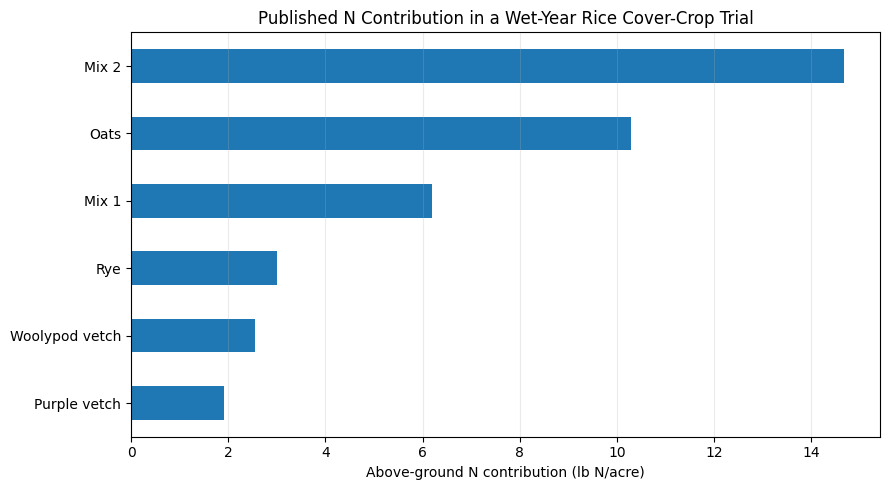

In [16]:
# Published Colusa results from the 2022-2023 rice cover-crop variety trial.
# Source: Brim-DeForest et al. (2023), Table 3.
covercrop_trial = pd.DataFrame([
    ["Purple vetch",   4.06,  47.35,  1.92, 10.11],
    ["Woolypod vetch", 4.27,  59.55,  2.54,  9.72],
    ["Mix 1",          3.66, 159.77,  6.19, 11.38],
    ["Mix 2",          2.06, 739.22, 14.68, 21.43],
    ["Oats",           1.60, 769.05, 10.29, 28.41],
    ["Rye",            1.66, 181.78,  3.01, 25.48],
], columns=[
    "Treatment",
    "Tissue_N_percent",
    "Dry_biomass_lb_ac",
    "N_contribution_lb_ac",
    "C_to_N_ratio",
])

display(covercrop_trial)

plot_trial = covercrop_trial.sort_values("N_contribution_lb_ac")

ax = plot_trial.plot(
    x="Treatment",
    y="N_contribution_lb_ac",
    kind="barh",
    figsize=(9, 5),
    legend=False,
)

ax.set_title("Published N Contribution in a Wet-Year Rice Cover-Crop Trial")
ax.set_xlabel("Above-ground N contribution (lb N/acre)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


### Interpretation — Establishment Changes the Vetch vs. Mix Decision

The wet-year trial shows why RiceShift should **not** hard-code "Vetch is always best" or "Mix is always best."

In the Colusa data:

- **Mix 2** produced the largest absolute N contribution among the displayed treatments (**14.68 lb N/acre**) because it produced much more biomass.
- **Purple vetch** had much higher tissue N concentration (**4.06% N**) and a lower C:N ratio (**10.11**), but poor biomass production in that particular season limited its total N contribution.
- **Oats** produced high biomass but had lower tissue N and a much higher C:N ratio.

More recent three-year Sacramento Valley work provides an important counterpoint: preliminary 2026 reporting from the completed multi-site trial states that **vetches continued to be among the best species for both biomass and nitrogen production**, and that planting before heavy rainfall was a key determinant of establishment (Brim-DeForest et al., 2026).

Together, these findings support a more useful rule:

> **Species choice alone is not enough. Winter moisture, establishment success, biomass production, and the farm's nitrogen / soil-cover objective determine the value of the cover crop.**

This connects directly back to H1: winter conditions are a distinct environmental window, so winter-specific environmental observations can help identify when establishment risk should receive greater attention.


### 7A-3. Economic Sensitivity — Fertilizer Savings Are Only Part of the Value

A 2022 UC Cooperative Extension / UC Davis cost study estimated **$156/acre** to establish and manage a winter cover crop in the Lower Sacramento Valley.

Important limitation: that study modeled a **vetch–pea–rye mixture in an annual crop rotation following processing tomatoes**, not a rice-specific vetch system. RiceShift therefore uses the value only as a **regional cost benchmark**, not as the cost of the RiceShift treatments.

Pettygrove and Williams (1996) reported vetch fertilizer-N replacement of **30–100 lb N/acre**, with an average near **50 lb N/acre**.

The following sensitivity calculation asks:

> **If fertilizer savings were the only economic benefit, what value per pound of N would be required to offset a $156/acre cover-crop benchmark cost?**

This is a break-even thought experiment, not a profitability estimate.


In [17]:
cover_crop_cost_benchmark = 156.0  # $/acre; regional benchmark, NOT rice-specific
n_replacement_scenarios = pd.DataFrame({
    "Scenario": ["Low reported replacement", "Approximate multi-study average", "High reported replacement"],
    "N_replaced_lb_ac": [30, 50, 100],
})

n_replacement_scenarios["Break_even_N_value_USD_per_lb"] = (
    cover_crop_cost_benchmark / n_replacement_scenarios["N_replaced_lb_ac"]
)

display(n_replacement_scenarios.round(2))

avg_n_replacement = 50.0
avg_break_even_n_price = cover_crop_cost_benchmark / avg_n_replacement

print(f"Regional cover-crop cost benchmark: ${cover_crop_cost_benchmark:.0f}/acre")
print(f"Published average vetch N replacement: ~{avg_n_replacement:.0f} lb N/acre")
print(
    "Break-even N value if fertilizer savings were the ONLY benefit: "
    f"${avg_break_even_n_price:.2f}/lb N"
)


,Scenario,N_replaced_lb_ac,Break_even_N_value_USD_per_lb
0,Low reported replacement,30,5.20
1,Approximate multi-study average,50,3.12
2,High reported replacement,100,1.56


Regional cover-crop cost benchmark: $156/acre
Published average vetch N replacement: ~50 lb N/acre
Break-even N value if fertilizer savings were the ONLY benefit: $3.12/lb N


### Economic interpretation

The sensitivity analysis prevents RiceShift from equating **"two crops"** with **"more profit."**

At the historical average of approximately **50 lb N/acre** replacement, fertilizer savings alone would need to be worth about **$3.12 per lb of N** to offset the entire **$156/acre regional cover-crop benchmark**.

That does **not** mean a rice-vetch system costs $156/acre, nor that it is unprofitable. The benchmark comes from a different Sacramento Valley rotation and is deliberately used only to establish scale.

Instead, it shows that the economic case for winter cover cropping can depend on multiple sources of value:

- fertilizer-N replacement,
- subsequent rice performance,
- nutrient retention,
- soil cover and erosion protection,
- soil organic matter / structure over time,
- weed or pest-management effects,
- incentive payments or market premiums,
- and the actual field-specific establishment and termination cost.

Therefore RiceShift should eventually evaluate **whole-system value**, not simply crop count or gross yield.

> **A successful rotation is not the strategy that produces the most crops; it is the strategy that improves total farm value without creating unacceptable agronomic, environmental, or market risk.**


### 7A-4. Evidence-Based Strategy Comparison

The published evidence now gives the second-stage RiceShift decision a more quantitative basis.

| Strategy | Evidence supporting the option | Main uncertainty |
|---|---|---|
| **Continuous Rice** | Avoids cover-crop establishment risk and cost; remains appropriate where winter rotation is environmentally or soil-constrained | Misses potential diversification, N-cycling, and soil-health benefits |
| **Winter Vetch** | Historical California experiments show substantial fertilizer-N replacement and altered rice N response; recent multi-site work continues to identify vetches as strong biomass/N performers | Establishment is sensitive to winter field conditions; economic value depends on fertilizer strategy and costs |
| **Winter Cover Crop Mix** | Mixtures can combine legumes and grasses; wet-year Colusa data show that a successful mixture can generate substantial biomass and total N | Mixture performance is species-, weather-, and establishment-dependent; a general regional cost benchmark is not treatment-specific |

RiceShift therefore does not assign an arbitrary numerical score to the three strategies.

The decision is hierarchical:

1. **NASA + crop history:** Is there an environmental reason to evaluate winter separately?
2. **SSURGO:** Is diversification agronomically plausible?
3. **Published trial evidence:** What benefit is realistic under successful establishment?
4. **Farmer objective / economics:** Is the desired benefit worth the field-specific cost and risk?

This is a stronger decision-support interpretation than selecting the treatment with the highest yield or the strongest single correlation.


## 7B. Local Economic and Policy Context — Does This Decision Matter in the Sacramento Valley?

The previous sections established environmental feasibility, soil constraints, and published agronomic value.

RiceShift also needs to answer a practical question:

> **Is rice economically important enough in the target region that a rotation decision could materially affect farm and regional outcomes?**

County Agricultural Commissioners publish annual crop reports with harvested acreage, yield, unit value, and gross commodity value. RiceShift uses the **2024 reports** for four major Sacramento Valley rice counties where the detailed rice line could be verified consistently:

- Sutter
- Colusa
- Butte
- Yuba

The values below are **gross commodity values**, not farm profit. They do not subtract production, marketing, equipment, labor, or land costs.

Glenn County also publishes a 2024 Crop & Livestock Report, but its detailed rice row was not included here because the source endpoint available during notebook preparation did not allow the rice-specific values to be verified reliably. RiceShift avoids filling that gap with an estimate.


In [18]:
# Verified 2024 county crop-report statistics for field rice.
# Values are entered directly from official county crop reports.
county_rice_2024 = pd.DataFrame([
    {
        "County": "Sutter",
        "Harvested_acres": 119000,
        "Yield_ton_per_ac": 4.36,
        "Unit_value_USD_per_ton": 370,
        "Gross_value_USD": 192030000,
        "Source": "Sutter County 2024 Crop & Livestock Report",
    },
    {
        "County": "Colusa",
        "Harvested_acres": 118386,
        "Yield_ton_per_ac": 4.65,
        "Unit_value_USD_per_ton": 363,
        "Gross_value_USD": 199830000,
        "Source": "Colusa County 2024 Crop & Livestock Report",
    },
    {
        "County": "Butte",
        "Harvested_acres": 71388,
        "Yield_ton_per_ac": 4.80,
        "Unit_value_USD_per_ton": 345,
        "Gross_value_USD": 118218390,
        "Source": "Butte County 2024 Crop & Livestock Report",
    },
    {
        "County": "Yuba",
        "Harvested_acres": 35820,
        "Yield_ton_per_ac": 4.40,
        "Unit_value_USD_per_ton": 331,
        "Gross_value_USD": 52168000,
        "Source": "Yuba County 2024 Crop & Livestock Report",
    },
])

county_rice_2024["Gross_value_USD_million"] = (
    county_rice_2024["Gross_value_USD"] / 1_000_000
)
county_rice_2024["Gross_value_per_harvested_acre_USD"] = (
    county_rice_2024["Gross_value_USD"] / county_rice_2024["Harvested_acres"]
)

display(
    county_rice_2024[
        [
            "County",
            "Harvested_acres",
            "Yield_ton_per_ac",
            "Unit_value_USD_per_ton",
            "Gross_value_USD_million",
            "Gross_value_per_harvested_acre_USD",
        ]
    ].round(2)
)

print(
    "Four-county verified total harvested rice acreage:",
    f"{county_rice_2024['Harvested_acres'].sum():,.0f} acres"
)
print(
    "Four-county verified gross field-rice value:",
    f"${county_rice_2024['Gross_value_USD'].sum()/1_000_000:.1f} million"
)
print(
    "Important: gross value is not net farm income or profit."
)


,County,Harvested_acres,Yield_ton_per_ac,Unit_value_USD_per_ton,Gross_value_USD_million,Gross_value_per_harvested_acre_USD
0,Sutter,119000,4.36,370,192.03,1613.70
1,Colusa,118386,4.65,363,199.83,1687.95
2,Butte,71388,4.80,345,118.22,1656.00
3,Yuba,35820,4.40,331,52.17,1456.39


Four-county verified total harvested rice acreage: 344,594 acres
Four-county verified gross field-rice value: $562.2 million
Important: gross value is not net farm income or profit.


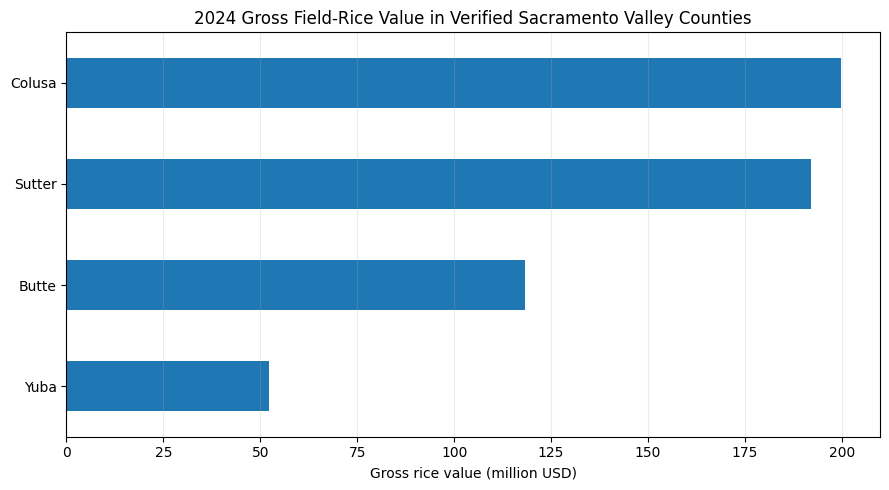

In [19]:
plot_county = county_rice_2024.sort_values("Gross_value_USD_million")

ax = plot_county.plot(
    x="County",
    y="Gross_value_USD_million",
    kind="barh",
    figsize=(9, 5),
    legend=False,
)

ax.set_title("2024 Gross Field-Rice Value in Verified Sacramento Valley Counties")
ax.set_xlabel("Gross rice value (million USD)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


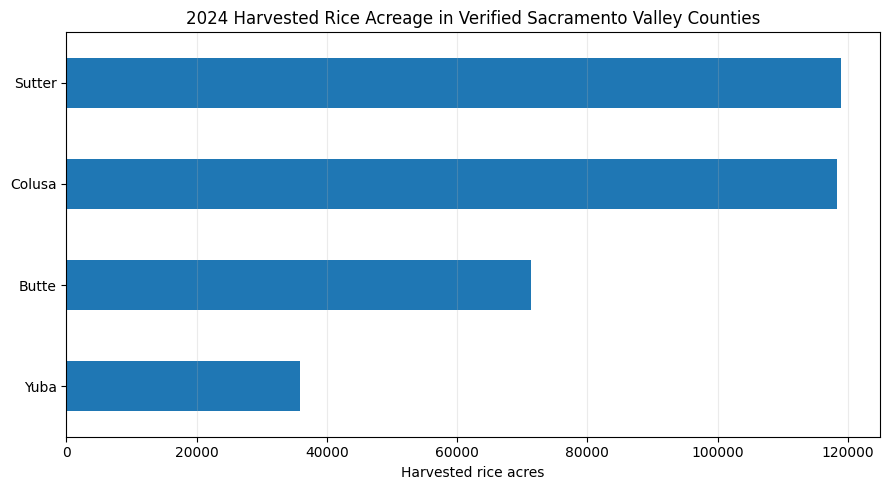

In [20]:
plot_acres = county_rice_2024.sort_values("Harvested_acres")

ax = plot_acres.plot(
    x="County",
    y="Harvested_acres",
    kind="barh",
    figsize=(9, 5),
    legend=False,
)

ax.set_title("2024 Harvested Rice Acreage in Verified Sacramento Valley Counties")
ax.set_xlabel("Harvested rice acres")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


### What the county statistics add to RiceShift

Across only these four verified counties, the 2024 crop reports represent approximately:

- **344,594 harvested rice acres**
- **$562.2 million in gross field-rice value**

This does not represent the entire Sacramento Valley, and gross value is not profit.

However, it demonstrates why rotation decisions cannot be judged only by whether a second crop can be grown.

A change in rice yield, input cost, or market value can affect a commodity that represents tens or hundreds of millions of dollars at the county level.

> **The relevant objective is whole-system farm value and resilience—not simply maximizing the number of crops per year.**

The county reports also show meaningful variation in rice unit value, from about **$331 to $370 per ton** across these four counties in 2024. That reinforces an important RiceShift principle: even similar yields do not automatically imply identical economic outcomes.


### 7B-1. Local Proof of Practice — Rice–Vetch Rotation Already Exists in Sutter County

The 2024 Sutter County Crop & Livestock Report profiles **Pleasant Grove Farms**, an organic operation using crop rotations and winter vetch in an actual Sacramento Valley rice system.

The report describes rice fields managed in a two-year cycle with a rest / green-fallow period. Vetch is seeded before rice harvest, grows through the winter, and is later incorporated into the soil, where the farm uses it to contribute nitrogen and organic matter.

The same report states that crop rotations are used to reduce pest, weed, and disease pressure.

This is important for RiceShift because it demonstrates that:

> **Rice–vetch management is not only a theoretical scenario constructed for the challenge; related management is already practiced commercially within the target region.**

RiceShift is therefore trying to improve the **screening and evidence structure around a real management choice**, not invent a new agronomic practice.


## 7C. Policy Alignment — Can a RiceShift Recommendation Connect to Existing Programs?

A decision-support prototype becomes more useful when its recommended practices connect to existing implementation pathways.

The **California Department of Food and Agriculture (CDFA) Healthy Soils Program (HSP)** currently supports both:

- **Cover Crop**
- **Conservation Crop Rotation**

as eligible cropland practices.

The 2026 HSP practice guidelines define Conservation Crop Rotation as a planned sequence of crops grown on the same ground and identify purposes including improving crop diversity, maintaining or increasing soil health and organic matter, reducing erosion, and improving water quality.

For 2026, the guidelines list Conservation Crop Rotation payment scenarios of:

- **$23.34/acre** for a basic rotation, supported for 3 years
- **$62.24/acre** for a specialty-crop scenario, supported for 3 years

The HSP participation guidance also states that both **single-species and mixed-species cover crops** are supported, and an eligible on-farm project may request up to **$150,000**, subject to program and per-practice limits.

These program rules can change over time, so RiceShift treats them as a **current implementation pathway**, not a permanent economic assumption.


In [21]:
policy_context = pd.DataFrame([
    {
        "Program / Resource": "CDFA Healthy Soils Program",
        "Practice / Support": "Conservation Crop Rotation",
        "2026 detail": "$23.34/ac basic or $62.24/ac specialty scenario; 3 years supported",
        "RiceShift role": "Potential implementation / incentive pathway",
    },
    {
        "Program / Resource": "CDFA Healthy Soils Program",
        "Practice / Support": "Cover Crop",
        "2026 detail": "Annual practice; single-species and mixed-species cover crops supported",
        "RiceShift role": "Direct policy alignment with Vetch / Mix strategies",
    },
    {
        "Program / Resource": "UCCE Sutter-Yuba Climate Smart Agriculture",
        "Practice / Support": "Technical assistance",
        "2026 detail": "Supports project design, applications, implementation, monitoring, and verification for CDFA incentive programs",
        "RiceShift role": "Local pathway from screening result to grower assistance",
    },
])

display(policy_context)


,Program / Resource,Practice / Support,2026 detail,RiceShift role
0,CDFA Healthy Soils Program,Conservation Crop Rotation,$23.34/ac basic or $62.24/ac specialty scenari...,Potential implementation / incentive pathway
1,CDFA Healthy Soils Program,Cover Crop,Annual practice; single-species and mixed-spec...,Direct policy alignment with Vetch / Mix strat...
2,UCCE Sutter-Yuba Climate Smart Agriculture,Technical assistance,"Supports project design, applications, impleme...",Local pathway from screening result to grower ...


### Why the policy layer matters

The policy data are **not used to force the statistical result** and are not added to H1–H3.

Instead, they answer a different question:

> **If RiceShift identifies a field or management situation where winter rotation deserves consideration, is there an existing pathway to help a grower act on that information?**

For the Sutter–Yuba area, UC Cooperative Extension's Climate Smart Agriculture Program provides local technical assistance for CDFA incentive programs, including support with project design, applications, implementation, monitoring, and verification.

This gives RiceShift a practical implementation chain:

```text
NASA + USDA + SSURGO evidence
        ↓
Rotation feasibility screen
        ↓
Agronomic / economic evidence
        ↓
Farmer objective
        ↓
Potential HSP-supported practice
        ↓
Local technical assistance
```

This does not mean every RiceShift recommendation would qualify for funding.

It shows that the prototype is aligned with **real conservation practices and an existing California implementation ecosystem**.


# 8. RiceShift Decision Framework

RiceShift separates **evidence validation** from the final management decision.

H1–H3 do not directly select a crop rotation. They establish what NASA observations can reliably contribute to the decision. Soil and published field evidence then determine whether the environmental opportunity is agronomically and economically meaningful.

```text
STEP 1 — HISTORICAL CONTEXT
Where has rice persisted?
USDA CDL + GIS
        ↓

STEP 2 — VALIDATE THE NASA EVIDENCE LAYER

H1 — Seasonal environmental separation
Winter vs. rice-season SMAP
Result: winter is a distinct environmental window
        ↓

H2 — Environmental relevance
MODIS indicators vs. NASS yield
Result: exploratory signals, especially ET/PET,
but no indicator survives FDR correction
        ↓

H3 — Predictive usefulness
NASA MODIS Ridge vs. historical-mean baseline
Result: only marginal improvement;
NASA variables alone are not a reliable yield predictor
        ↓

NASA EVIDENCE INTERPRETATION
Useful as environmental decision-support evidence,
but insufficient as a stand-alone recommendation model
        ↓

STEP 3 — SCREEN ROTATION FEASIBILITY

Long-term crop history
        +
Winter environmental conditions
        +
SSURGO soil constraints
        ↓

Is winter rotation a plausible option?
        ↓
      ┌───────────────┴────────────────┐
      ↓                                ↓
     NO                               YES
      ↓                                ↓
Continuous Rice              Consider Winter Rotation
remains a candidate                    ↓

STEP 4 — QUANTIFY AGRONOMIC VALUE

Published California field evidence:
• Vetch fertilizer-N replacement
• Rice yield response to N after vetch
• Vetch / mixture biomass and N contribution
• Regional cover-crop cost sensitivity
• County-level rice economic context
• Existing policy / technical-assistance pathways
                                       ↓

STEP 5 — APPLY FARMER OBJECTIVE
                                       ↓
                         ┌─────────────┴─────────────┐
                         ↓                           ↓
              Biological nitrogen          Diversity / soil cover /
                 contribution               nutrient retention /
                         ↓                  multiple functions
                    Winter Vetch                    ↓
                                            Cover Crop Mix
```

## What the framework means

The evidence layers now have distinct jobs:

- **H1 provides strong support** for treating winter as a separate environmental management window.
- **H2 identifies potentially useful NASA environmental signals**, but the associations remain exploratory after multiple-testing correction.
- **H3 shows that the regional NASA indicators alone are not sufficient for reliable yield prediction.**
- **SSURGO acts as a feasibility constraint**, preventing environmental opportunity from being confused with agronomic suitability.
- **Published California field trials quantify potential agronomic value**, particularly fertilizer-N replacement, subsequent rice response, biomass, and N contribution.
- **Economic sensitivity prevents "more crops" from being treated automatically as "more profit."**
- **County crop reports establish local economic relevance**, showing that rice represents hundreds of millions of dollars in gross value across the verified counties.
- **Existing California programs provide an implementation pathway**, because cover crops and conservation crop rotations are supported Healthy Soils Program practices and local UCCE technical assistance exists in Sutter-Yuba.

Therefore, RiceShift does not use satellite data as an automatic crop-selection engine.

Instead, NASA observations provide the **environmental evidence layer**, while crop history, soil feasibility, published field evidence, costs, and farmer objectives determine whether a rotation remains attractive.

## What RiceShift actually claims

RiceShift does **not** claim:

- that correlation proves causality,
- that NASA observations alone can predict field-level rice yield,
- that regional statistics are equivalent to individual-field recommendations,
- that a $156/acre non-rice cost benchmark is the actual cost of a rice cover crop,
- or that Continuous Rice, Vetch, or a Cover Crop Mix is universally superior.

RiceShift **does** demonstrate a transparent way to combine NASA Earth observations with local soil data and California agronomic evidence to structure a crop-rotation decision.

> **Use NASA data to identify environmental opportunity, soil and crop history to test feasibility, published field evidence to estimate agronomic value, and farmer-specific economics and objectives to choose among feasible options.**


# 9. Integrated Evidence Summary

The previous sections tested and quantified different parts of the RiceShift decision framework.

At this point, the goal is **not to search for another correlation**.

Instead, this section asks:

> **What do the combined results actually allow RiceShift to claim, and what additional value is supported by published California field experiments?**

The evidence layers have different roles:

- **H1 — Seasonal SMAP difference:** establishes whether winter is a distinct environmental management window.
- **H2 — MODIS vs. rice yield:** tests whether NASA environmental indicators show outcome-relevant signals.
- **H3 — Out-of-sample yield prediction:** tests whether those signals are strong enough for unseen-year prediction.
- **Soil suitability screen:** tests whether published rotation-associated soil conditions are restrictive.
- **Published agronomic evidence:** quantifies fertilizer-N replacement, subsequent rice yield response, and Vetch/Mix biomass and N performance.
- **Economic sensitivity:** tests whether fertilizer savings alone could plausibly justify a regional cover-crop cost benchmark.
- **County economic context:** establishes the real scale of rice production and gross value in the target region.
- **Policy alignment:** checks whether the screened practices connect to current California conservation programs and local technical assistance.

The purpose of the following table is to distinguish between:

- **strong environmental evidence**
- **exploratory evidence**
- **limited predictive value**
- **agronomic constraints**
- **published agronomic/economic value**
- **regional economic relevance**
- and **implementation pathways**

so that the final crop-rotation framework does not overstate what any one data source can support.


In [22]:
h1_supported = h1_p < 0.05
h2_fdr_count = int((h2_results["q_value_fdr"] < 0.05).sum())

h3_beats_baseline = nasa_metrics["MAE"] < baseline_metrics["MAE"]
h3_reliable = (
    h3_beats_baseline
    and mae_improvement_pct >= 5.0
    and nasa_metrics["R2"] > 0
)

soil_all3_pct = (
    (soil_screen["criteria_matched"] == 3).mean() * 100
)

strongest_h2 = h2_results.iloc[0]

# Published evidence added in Section 7A.
published_avg_n_replacement = 50.0
published_n_range = "30–100 lb N/acre"
yield_gain_no_n = float(
    vetch_rice_response.loc[
        vetch_rice_response["N_applied_lb_ac"] == 0,
        "Vetch_yield_difference_cwt_ac"
    ].iloc[0]
)
yield_gain_high_n = float(
    vetch_rice_response.loc[
        vetch_rice_response["N_applied_lb_ac"] == 120,
        "Vetch_yield_difference_cwt_ac"
    ].iloc[0]
)

final_summary = pd.DataFrame([
    {
        "Analysis": "H1 — Seasonal SMAP difference",
        "Evidence": (
            f"Wilcoxon p={h1_p:.4f}; "
            f"median Δ={h1_median_diff:.4f} m³/m³; "
            f"rank-biserial={rank_biserial:.3f}"
        ),
        "Interpretation": (
            "Strong support: winter is a distinct environmental window"
            if h1_supported
            else "No significant seasonal difference detected"
        ),
    },

    {
        "Analysis": "H2 — MODIS vs yield",
        "Evidence": (
            f"{h2_fdr_count} of {len(h2_results)} indicators have FDR q<0.05; "
            f"strongest={strongest_h2['indicator']} "
            f"(rho={strongest_h2['rho']:.3f}, "
            f"raw p={strongest_h2['p_value']:.4f}, "
            f"q={strongest_h2['q_value_fdr']:.4f})"
        ),
        "Interpretation": (
            "FDR-controlled association detected"
            if h2_fdr_count > 0
            else "Exploratory environmental signals only; no confirmed association after FDR correction"
        ),
    },

    {
        "Analysis": "H3 — NASA yield prediction",
        "Evidence": (
            f"NASA MAE={nasa_metrics['MAE']:.1f}; "
            f"baseline MAE={baseline_metrics['MAE']:.1f}; "
            f"MAE improvement={mae_improvement_pct:.1f}%; "
            f"NASA R²={nasa_metrics['R2']:.3f}"
        ),
        "Interpretation": (
            "Meaningful out-of-sample predictive improvement"
            if h3_reliable
            else (
                "Marginal improvement over baseline, but insufficient for reliable yield prediction"
                if h3_beats_baseline
                else
                "NASA model does not outperform the historical-mean baseline"
            )
        ),
    },

    {
        "Analysis": "Soil suitability screen",
        "Evidence": (
            f"{soil_all3_pct:.1f}% of complete SSURGO map-unit records "
            "match all 3 published rotation-associated soil criteria"
        ),
        "Interpretation": (
            "Soil appears to be an important feasibility constraint; "
            "record-based screen, not an acreage or field-level estimate"
        ),
    },

    {
        "Analysis": "Published Vetch agronomic value",
        "Evidence": (
            f"N replacement reported at {published_n_range} "
            f"(~{published_avg_n_replacement:.0f} average); "
            f"5-yr yield difference={yield_gain_no_n:+.0f} cwt/ac at 0 N "
            f"and {yield_gain_high_n:+.0f} cwt/ac at 120 N"
        ),
        "Interpretation": (
            "Vetch value is strongly linked to fertilizer-N management; "
            "benefit is not equivalent to simply adding a second harvested crop"
        ),
    },

    {
        "Analysis": "Economic sensitivity",
        "Evidence": (
            f"Regional cover-crop benchmark=${cover_crop_cost_benchmark:.0f}/ac; "
            f"at ~50 lb N/ac replacement, fertilizer-only break-even="
            f"${avg_break_even_n_price:.2f}/lb N"
        ),
        "Interpretation": (
            "Fertilizer savings alone may not justify rotation cost; "
            "whole-system benefits, risks, incentives, and field-specific costs matter"
        ),
    },
])

display(final_summary)


,Analysis,Evidence,Interpretation
0,H1 — Seasonal SMAP difference,Wilcoxon p=0.0020; median Δ=0.1305 m³/m³; rank...,Strong support: winter is a distinct environme...
1,H2 — MODIS vs yield,0 of 6 indicators have FDR q<0.05; strongest=E...,Exploratory environmental signals only; no con...
2,H3 — NASA yield prediction,NASA MAE=208.6; baseline MAE=210.2; MAE improv...,"Marginal improvement over baseline, but insuff..."
3,Soil suitability screen,3.2% of complete SSURGO map-unit records match...,Soil appears to be an important feasibility co...
4,Published Vetch agronomic value,N replacement reported at 30–100 lb N/acre (~5...,Vetch value is strongly linked to fertilizer-N...
5,Economic sensitivity,Regional cover-crop benchmark=$156/ac; at ~50 ...,Fertilizer savings alone may not justify rotat...


### Integrated interpretation

The combined results show that the evidence layers do not contribute equally to the final decision.

- **H1 provides strong evidence** that winter should be treated as a separate environmental management window.
- **H2 provides exploratory evidence** that some MODIS-derived environmental variables may be related to rice yield, but the current 19-year sample does not confirm any individual indicator after multiple-testing correction.
- **H3 shows limited predictive value**: the NASA MODIS Ridge model performs only marginally better than the historical-mean baseline and does not support a strong stand-alone yield-prediction claim.
- **The SSURGO screen identifies soil as an important feasibility constraint**, because only a small fraction of complete map-unit records match all three published rotation-associated soil criteria.
- **Published California rice experiments add direct agronomic evidence** that a successful vetch cover crop can replace substantial fertilizer N and change the following rice crop's N-response curve.
- **Recent cover-crop trials show that establishment matters**: mixtures may produce large biomass and N in some conditions, while multi-year reporting also identifies vetches among the strongest biomass/N performers.
- **The economic sensitivity check shows why crop count is not enough**: a rotation must be judged on whole-system value, not simply on whether two crops can be grown.
- **County crop reports establish that the decision is economically material**: the four verified 2024 county reports alone represent about 344,594 harvested rice acres and $562.2 million in gross field-rice value.
- **Current policy creates a plausible implementation pathway**: CDFA HSP supports Cover Crop and Conservation Crop Rotation practices, while UCCE Sutter-Yuba provides local climate-smart-agriculture technical assistance.

Taken together, the strongest conclusion is:

> **NASA observations can identify and characterize environmental opportunity, but the rotation decision becomes credible only after environmental evidence is combined with soil feasibility, field-trial agronomy, and economics.**

RiceShift therefore follows a hierarchical decision:

**NASA environmental evidence → crop-history and soil feasibility → published agronomic value → local economic context → farmer-specific economics and objectives → implementation pathway**

before screening between **Continuous Rice** and **Consider Winter Rotation**, and only then distinguishing between **Vetch** and a **Cover Crop Mix**.

Importantly, RiceShift intentionally does **not** merge unrelated published trial means with the regional NASA time series just to obtain a stronger correlation. The datasets answer different questions and are combined at the decision level where their evidence is valid.


# 10. Limitations and Next Steps

The integrated results define both the value and the current limits of RiceShift.

H1 provides strong evidence that winter should be treated as a separate environmental management window. H2 identifies exploratory NASA environmental signals, while H3 shows that those signals alone are not sufficient for reliable yield prediction. The SSURGO screen shows that soil feasibility can constrain diversification. Published California field experiments then provide a separate quantitative layer for understanding potential N, yield, biomass, and cost effects.

Several limitations remain.

1. **Regional aggregation**  
   NASS yield is an annual California-level outcome, while satellite and crop-history features are regional summaries. The observed relationships should not be interpreted as individual-field effects.

2. **Small sample size**  
   H2 and H3 use only **19 annual observations**, while the complete paired SMAP winter-to-rice comparison uses **10 years**. This is why RiceShift uses simple statistical tests, regularized regression, and leave-one-year-out validation rather than complex machine-learning models.

3. **Observational data**  
   Correlation, statistical significance, and predictive performance do not establish agronomic causality. Field experiments are needed to determine whether changing a management practice causes a yield or soil response.

4. **Limited predictive performance**  
   The NASA MODIS Ridge model improved MAE over the historical-mean baseline by only approximately **0.8%**, and its cross-validated R² remained below zero. NASA indicators therefore should not be interpreted as a reliable stand-alone yield-prediction model in the current dataset.

5. **Soil geometry in the compact bundle**  
   The SSURGO compact table does not include field-boundary geometry. The soil analysis summarizes map-unit records and does not estimate the percentage of Sacramento Valley acreage or individual farms that satisfy the published criteria.

6. **Published trials are not the same statistical population as the NASA time series**  
   The vetch and cover-crop experiments were conducted at specific sites, years, and management regimes. RiceShift therefore does not pool those treatment means with the regional MODIS / SMAP annual series or calculate artificial cross-dataset correlations.

7. **The $156/acre cost is a regional benchmark, not a rice-specific treatment cost**  
   The 2022 Lower Sacramento Valley study modeled a vetch–pea–rye mixture in an annual crop rotation following processing tomatoes. It provides useful scale for sensitivity analysis but is not the cost of the RiceShift Vetch or Mix strategy.

8. **Vetch vs. mixture remains context-dependent**  
   The published evidence shows meaningful differences in N concentration, biomass, total N contribution, and establishment response, but it does not establish a universal economic winner. Field-specific cost, drainage, timing, fertilizer price, incentive programs, and grower objectives remain necessary.


9. **County crop-report values are gross values, not profitability**  
   The county reports quantify harvested acreage, yield, unit value, and gross commodity value. They do not subtract production, marketing, labor, land, equipment, or financing costs and therefore cannot be interpreted as net farm income.

10. **The four-county table is not the entire Sacramento Valley**  
    Sutter, Colusa, Butte, and Yuba were included because their 2024 rice-specific statistics could be verified consistently. Glenn County also publishes a 2024 crop report, but its detailed rice row was not entered because it could not be verified reliably through the source endpoint used during notebook preparation.

11. **Policy incentives are time-sensitive**  
    Healthy Soils Program eligibility, payment rates, project caps, and application procedures can change. RiceShift uses the 2026 program rules only to demonstrate an existing implementation pathway; operational use should always check the current program guidance.

## Next Steps

A more operational version of RiceShift could extend the present framework by adding:

- field-boundary geometry,
- field-level SSURGO spatial joins,
- field-specific winter drainage and moisture conditions,
- actual seed / planting / termination costs for the selected cover crop,
- current fertilizer-N prices and incentive payments,
- rice quality and price effects,
- farmer-specific objectives,
- replicated field-trial observations linked spatially to NASA variables,
- county-level net-return / enterprise-budget data rather than gross crop value alone,
- and current incentive-program rules and local technical-assistance availability.

These additions would allow RiceShift to move from **regional evidence screening** toward **field-specific whole-farm rotation optimization**.

The current experiment establishes the defensible first step:

> **Use NASA observations to identify environmental opportunity, crop history and soil to test feasibility, published agronomic evidence to estimate potential value, and farm-specific economics to decide whether a rotation actually improves the whole system.**


# References

## Literature and agronomic evidence

Al-Khatib, K., Grettenberger, I., Linquist, B., Harrell, D., Espino, L., Brim-DeForest, W., & Leinfelder-Miles, M. (2023). *Rice production manual*. University of California Agriculture and Natural Resources, in collaboration with the California Rice Research Board. https://agronomy-rice.ucdavis.edu/rice-production-workshop-manual

Brim-DeForest, W., Leinfelder-Miles, M., Linquist, B., Espino, L., Pittelkow, C., Light, S., Rosenberg, S., Clark, T., Baez Vega, C., & Guan, T. (2023). *Cover crop variety trial in rice: 2023 annual report*. University of California Cooperative Extension / California Rice Research Board. https://agronomy-rice.ucdavis.edu/sites/g/files/dgvnsk11966/files/inline-files/Cover%20Crop%20Variety%20Trial%20in%20Rice_0.pdf

Brim-DeForest, W. B., Janish, S. M., & Espino, L. A. (2026, February 9). *Fall update: Rice field research projects in the Sacramento Valley*. UC Rice Blog, University of California Agriculture and Natural Resources. https://ucanr.edu/blog/uc-rice-blog/article/fall-update-rice-field-research-projects-sacramento-valley

Light, S., Lloyd, M., Berris, H., Stewart, D., & Goodrich, B. (2022). *Estimated costs and potential benefits for a winter cover crop in an annual crop rotation: Lower Sacramento Valley—2022*. University of California Agriculture and Natural Resources Cooperative Extension & UC Davis Department of Agricultural and Resource Economics. https://coststudyfiles.ucdavis.edu/uploads/pub/2022/09/28/2022covercropsbenefits.pdf

Pettygrove, G. S., & Williams, J. F. (1996). *Nitrogen-fixing cover crops for California rice production*. University of California Cooperative Extension, Department of Land, Air and Water Resources, University of California, Davis. https://agronomy-rice.ucdavis.edu/sites/g/files/dgvnsk11966/files/inline-files/218860.pdf

Rosenberg, S., Crump, A., Brim-DeForest, W., Linquist, B., Espino, L., Al-Khatib, K., Leinfelder-Miles, M. M., & Pittelkow, C. M. (2022). Crop rotations in California rice systems: Assessment of barriers and opportunities. *Frontiers in Agronomy, 4*, 806572. https://doi.org/10.3389/fagro.2022.806572

Salvato, L. A., Pittelkow, C. M., O'Geen, A. T., & Linquist, B. A. (2024). A geospatial assessment of soil properties to identify the potential for crop rotation in rice systems. *Agriculture, Ecosystems & Environment, 359*, 108753. https://doi.org/10.1016/j.agee.2023.108753


Butte County Department of Agriculture / Weights & Measures. (2025). *2024 Butte County crop and livestock report*. https://www.buttecounty.ca.gov/ArchiveCenter/ViewFile/Item/899

California Department of Food and Agriculture. (2026). *Healthy Soils Program 2026 practice guidelines*. https://www.cdfa.ca.gov/oars/healthysoils/docs/HSP_2026_Practice_Guidelines_July_2026_Final_ADA.pdf

California Department of Food and Agriculture. (2026). *How to participate in the Healthy Soils Program*. https://www.cdfa.ca.gov/oars/healthysoils/docs/how_to_participate_in_hsp.pdf

Colusa County Agricultural Commissioner. (2025). *2024 Colusa County crop and livestock report*. https://www.countyofcolusaca.gov/DocumentCenter/View/19595/Crop-Report-2024

Sutter County Agricultural Commissioner. (2025). *2024 Sutter County crop & livestock report*. https://www.sutter.gov/home/showpublisheddocument/8881/638972432633530000

University of California Cooperative Extension, Sutter-Yuba Counties. (2026). *Climate Smart Agriculture Program*. https://ucanr.edu/county/cooperative-extension-sutter-yuba-counties/climate-smart-agriculture-program

Yuba County Agricultural Commissioner. (2025). *2024 Yuba County crop & livestock report*. https://www.yuba.gov/departments/agricultural_commissioner_sealer_of_weights_measures/crop_reports.php

## Primary data sources used by RiceShift

- NASA MODIS — vegetation, evapotranspiration, and land-surface-temperature products
- NASA SMAP — Enhanced L3 Radiometer Daily 9 km Soil Moisture
- USDA NASS Cropland Data Layer (CDL)
- USDA NASS Quick Stats
- USDA NRCS SSURGO

The repository documents the complete Steps 20–30 preparation pipeline used to create `data.zip`.

## How external evidence is used

The UC Davis / UC ANR trial and cost values are entered directly into the notebook as small, transparent DataFrames with their sources shown above.

They are **not** treated as additional NASA observations and are **not** merged statistically with the MODIS / SMAP annual series. Their role is to quantify the agronomic and economic evidence used after the environmental and soil feasibility screens.
